In [1]:
from visualize import Embedding

# baseline ro_en
baseline = Embedding(
        name="baseline (ro-en)",
        base_path='/ivi/ilps/projects/cnmt/knn-mt-dispersion/datastores/model_512_no_dispersion/',
        features_path='train.features.npy',
        targets_path='410.train.targets.npy',
        yaml_path="410.roen.faiss_L2_IVFPQindex_cs64_nprobe32_d512_nc4096_metadata.yaml",
        faiss_path='410.roen.faiss_L2_IVFPQindex_cs64_nprobe32_d512_nc4096'
    )
# dispersion ro_en
dispersion = Embedding(
        name="dispersion (ro-en)",
        base_path='/ivi/ilps/projects/cnmt/knn-mt-dispersion/datastores/model_512_dispersion/',
        features_path='582.train.features.npy',
        targets_path='582.train.targets.npy',
        yaml_path="582.roen.faiss_L2_IVFPQindex_cs64_nprobe32_d512_nc2048_meta.yaml",
        faiss_path='582.roen.faiss_L2_IVFPQindex_cs64_nprobe32_512_4096'
    )
baseline.load()
dispersion.load()

/home/stroshi/miniconda3/envs/evgeniia/lib/python3.8/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Namespace(code_size=64, corse_index='FlatL2', datastore='IVFPQ', dim=512, nclusters=4096, nprobe=32, ntotal=21507934)
Namespace(code_size=64, corse_index='FlatL2', datastore='IVFPQ', dim=512, features_model='/ivi/ilps/personal/etokarc/models/translation/00582_ro_en_transformer_dispersion_ft/checkpoint_best.pt', nclusters=2048, nprobe=32, ntotal=21507934)


## Plans
-  cluster entropy (as a discrete histogram of points per center) and (related) average and median cluster size
-  total kmeans energy sum_i d^2 (x_i, q(x_i))
-  per-cluster energy for cluster z = sum_{x : q(x)=z} d^2(x, z)}
-  For every point, what % of its k nearest neighbors lie in the same cluster as the point (fix k to be what is used in decoding)
-  clustering evaluation metrics from sklearn (eg v -measure etc, using the token labels ("values" in the kv store) as labels (edited) 

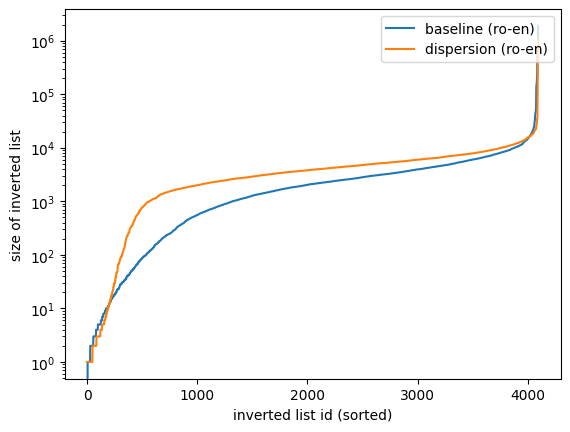

baseline (ro-en)
          mean  median
0  5250.960449  2109.0

dispersion (ro-en)
          mean  median
0  5250.960449  3894.5


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import scipy as sp

from typing import List, Tuple

def cluster_entropy(embedding: Embedding):
    """
    Returns: IVF cluster sizes
    """
    knn_index = embedding.knn_index
    sizes = []
    # print(knn_index.invlists.code_size)
    # print(knn_index.invlists.nlist)
    for i in range(knn_index.invlists.nlist):
        sizes.append(knn_index.invlists.list_size(i))
    return sizes

def make_sizes_plot(baseline: Embedding, dispersion: Embedding):
    """
    Plot the sizes of the IVF clusters for the baseline and dispersion embeddings.
    default: sorted mode by the size of the inverted list
    """
    sizes_baseline = cluster_entropy(baseline)
    sizes_dispersion = cluster_entropy(dispersion)
    sizes_baseline = np.sort(sizes_baseline)
    sizes_dispersion = np.sort(sizes_dispersion)

    fig, ax = plt.subplots()
    plt.plot(sizes_baseline, label=baseline.name)
    plt.plot(sizes_dispersion, label=dispersion.name)
    ax.legend(loc='upper right')
    ax.set_ylabel('size of inverted list')
    ax.set_xlabel('inverted list id (sorted)')
    # log scale
    ax.set_yscale('log')
    plt.show()


def make_mean_median_cluster_sizes(embedding) -> pd.DataFrame:
    sizes = cluster_entropy(embedding)
    sizes = np.array(sizes)
    mean = np.mean(sizes)
    median = np.median(sizes)
    df = pd.DataFrame({'mean': [mean], 'median': [median]})
    return df


########### script. ##########

make_sizes_plot(baseline, dispersion)

# make mean and median cluster sizes
df_baseline = make_mean_median_cluster_sizes(baseline)
df_dispersion = make_mean_median_cluster_sizes(dispersion)

print(baseline.name)
print(df_baseline)
print()
print(dispersion.name)
print(df_dispersion)


- why mean is *exactly* the same for baseline and dispersion?
- dispersion makes clusters more equal in size

Baseline total kmeans energy: 2305178.5 +- 9513.938178116949
Dispersion total kmeans energy: 1989874.0 +- 12606.977461065426


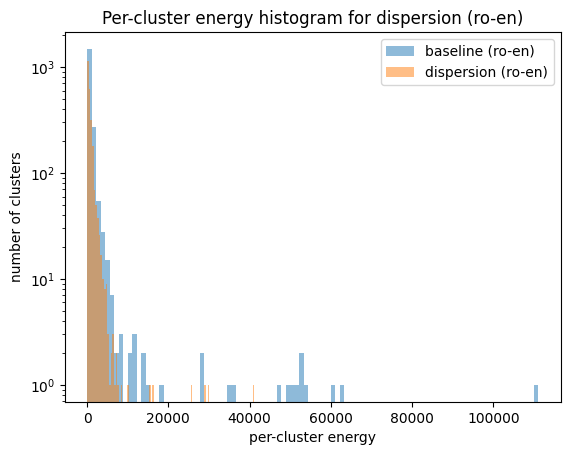

In [3]:



def sample_d_i_ivf_kmeans(embedding, n_crop=1000000, n_sample=10000, seed=0) -> Tuple[np.ndarray, np.ndarray]:
    """Return:
    List of (D, I) for sampled vector in the dataset
    Ds are squeared distances to the cluster centers
    Is are the cluster ids
    """
    # save values and corresponding cluster_id(feature)
    keys = embedding.keys[:n_crop]  # use more for final plot
    np.random.seed(seed)
    indices = np.random.choice(len(keys), n_sample, replace=False)
    keys = keys[indices]
    D, I = embedding.knn_index.quantizer.search(keys, k=1) # (n_first, 1), (n_first, 1)
    return D.flatten(), I.flatten()


def total_kmeans_energy(embedding) -> Tuple[float, float]:
    """
    Returns:
    total kmeans energy sum_i d^2 (x_i, q(x_i))
    lower and upper confidence intervals
    """
    # total kmeans energy with std
    energies = []
    for seed in range(5):
        dss, _ = sample_d_i_ivf_kmeans(embedding, n_crop=1000000, n_sample=10000, seed=seed)
        energy = np.sum(dss)
        energies.append(energy)
    # calculate mean and std
    # for the energies
    mean = np.mean(energies)
    std = sp.stats.sem(energies)
    return mean, std


def per_cluster_energy(embedding) -> List[float]:
    #  per-cluster energy for cluster z = sum_{x : q(x)=z} d^2(x, z)}
    dss, ids = sample_d_i_ivf_kmeans(embedding, n_crop=1000000, n_sample=10000)
    energies = []
    for id in np.sort(np.unique(ids)):
        indices_with_id = np.where(ids == id)[0]
        dss_for_id = dss[indices_with_id]
        energies.append(dss_for_id.sum())
    return energies


print("Baseline total kmeans energy: {} +- {}".format(*total_kmeans_energy(baseline)))
print("Dispersion total kmeans energy: {} +- {}".format(*total_kmeans_energy(dispersion)))


# make a histogram of the per-cluster energy
def make_per_cluster_energy_histogram(energies, embedding, ax):
    ax.hist(energies, bins=100, label=embedding.name, alpha=0.5)
    ax.set_xlabel('per-cluster energy')
    ax.set_ylabel('number of clusters')
    ax.set_title(f'Per-cluster energy histogram for {embedding.name}')
    ax.set_yscale('log')

fig, ax = plt.subplots()
make_per_cluster_energy_histogram(
    per_cluster_energy(baseline),
    baseline, ax
)
make_per_cluster_energy_histogram(
    per_cluster_energy(dispersion),
    dispersion, ax
)
ax.legend()
plt.show()


- for dispersion it seems that the energy is lower. stds over 5 seeds to not intersect (check that I do it correctly!) - (2305178.5 - 19027.875), (1989874.0 + 25213.955078125) = (2286150.625, 2015087.955078125)
- Currently to speed up things I crop first N points to speed up reading from the disk, but should sample from all points for the final run?

Mean same cluster: 98.6 +- 0.16617317083254113
Mean same cluster: 91.4 +- 0.2888333168749537
Mean same cluster: 86.925 +- 0.3492968317281608
Mean same cluster: 84.0625 +- 0.38319033875757286
Mean same cluster: 82.10125 +- 0.4007040677825563
Mean same cluster: 96.38 +- 0.2641837970347976
Mean same cluster: 92.14 +- 0.3182205726639516
Mean same cluster: 89.285 +- 0.35494781671468006
Mean same cluster: 87.4425 +- 0.3783969154143821
Mean same cluster: 85.975 +- 0.3938793002693034


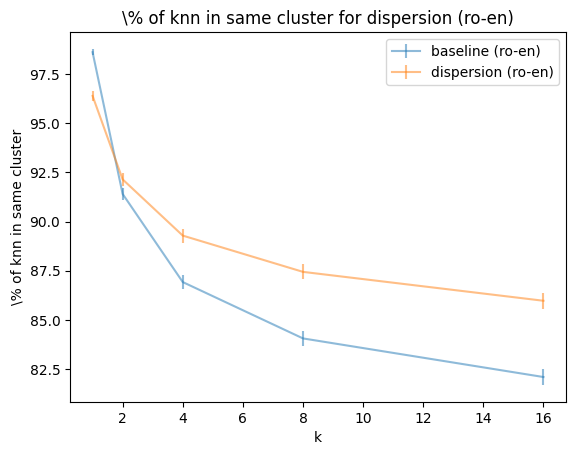

In [ ]:


def extract_k_neighbors(embedding, k_neignbors=8, n_crop=100000, n_sample=1000, seed=0) -> Tuple[np.ndarray, np.ndarray]:
    """Return:
    List of (D, I) for sampled vector in the dataset
    Ds are squeared distances to the cluster centers
    Is are the cluster ids
    """
    # save values and corresponding cluster_id(feature) 
    keys = embedding.keys[:n_crop]  # use more for final plot
    np.random.seed(seed)
    indices = np.random.choice(len(keys), n_sample, replace=False)
    keys = keys[indices]
    D, I = embedding.knn_index.search(keys, k=k_neignbors) # (n_first, 1), (n_first, 1)
    assert D.shape == (n_sample, k_neignbors)
    assert I.shape == (n_sample, k_neignbors)
    return keys, D, I


def same_knn_cluster(embedding, k_neignbors=8, n_crop=100000, n_sample=1000, seed=0) -> np.ndarray:
    # For every point, what % of its k nearest neighbors lie in the same cluster as the point (fix k to be what is used in decoding)
    # extract k neighbors and their cluster ids
    keys, knn_d, knn_i = extract_k_neighbors(embedding, k_neignbors=k_neignbors, n_crop=n_crop, n_sample=n_sample, seed=seed)
    cluster_d, cluster_i = embedding.knn_index.quantizer.search(keys, k=1) # (n_first, 1), (n_first, 1)
    
    # get embeddings of knns
    knn_keys = embedding.keys[knn_i]
    flat_knn_keys = knn_keys.reshape(-1, knn_keys.shape[-1])

    knn_cluster_d, knn_cluster_i = embedding.knn_index.quantizer.search(flat_knn_keys, k=1) # (n_first, 1), (n_first, 1)
    knn_cluster_d = knn_cluster_d.reshape(knn_i.shape)
    knn_cluster_i = knn_cluster_i.reshape(knn_i.shape)

    # compare cluster_i vs knn_cluster_i
    matched_clusters = knn_cluster_i == cluster_i
    # calculate the percentage of knn that are in the same cluster
    same_cluster = np.sum(matched_clusters, axis=1) / k_neignbors * 100
    # calculate the mean and std
    mean = np.mean(same_cluster)
    std = sp.stats.sem(same_cluster)
    print("Mean same cluster: {} +- {}".format(mean, std))
    return (mean, std)


def plot_same_knn_cluster(ax, embedding, n_crop=100000, n_sample=1000, seed=0, nprobe=32):
    original_nprobe = embedding.knn_index.nprobe
    embedding.knn_index.nprobe = nprobe
    try:
        # extract k
        means = []
        stds = []
        ks = []
        for k in (1, 2, 4, 8, 16):
            (mean, std) = same_knn_cluster(embedding, k_neignbors=k, n_crop=n_crop, n_sample=n_sample, seed=seed)
            means.append(mean)
            stds.append(std)
            ks.append(k)
        # plot the means and stds
        ax.errorbar(ks, means, yerr=stds, label=embedding.name, alpha=0.5)
        ax.set_xlabel('k')
        ax.set_ylabel(f'\% of knn in same cluster')
        ax.set_title(f'\% of knn in same cluster for {embedding.name}')
        ax.legend()
    finally:
        # reset nprobe
        embedding.knn_index.nprobe = original_nprobe

    assert embedding.knn_index.nprobe == original_nprobe

# use n_sample=500 for faster plot
fig, ax = plt.subplots()
plot_same_knn_cluster(ax, baseline, n_crop=1000000, n_sample=5000, seed=0, nprobe=32)
plot_same_knn_cluster(ax, dispersion, n_crop=1000000, n_sample=5000, seed=0, nprobe=32)
plt.show()


For a point x, first, rank the centroids by distance to q(x). let's call this ranking R. (so the centroid closest to q(x) is 1, ie R(q(x))=1. the second-closest is 2, so R(argmin_z {d(z, x): z != q(x))} = 2, etc). In case of ties take the average ranking among the ties.



In [ ]:


# def extract_k_neighbors(embedding, k_neignbors=8, n_crop=100000, n_sample=1000, seed=0) -> Tuple[np.ndarray, np.ndarray]:
#     """Return:
#     List of (D, I) for sampled vector in the dataset
#     Ds are squeared distances to the cluster centers
#     Is are the cluster ids
#     """
#     # save values and corresponding cluster_id(feature) 
#     keys = embedding.keys[:n_crop]  # use more for final plot
#     np.random.seed(seed)
#     indices = np.random.choice(len(keys), n_sample, replace=False)
#     keys = keys[indices]
#     D, I = embedding.knn_index.search(keys, k=k_neignbors) # (n_first, 1), (n_first, 1)
#     assert D.shape == (n_sample, k_neignbors)
#     assert I.shape == (n_sample, k_neignbors)
#     return keys, D, I


# def same_knn_cluster(embedding, k_neignbors=8, n_crop=100000, n_sample=1000, seed=0) -> np.ndarray:
#     # For every point, what % of its k nearest neighbors lie in the same cluster as the point (fix k to be what is used in decoding)
#     # extract k neighbors and their cluster ids
#     keys, knn_d, knn_i = extract_k_neighbors(embedding, k_neignbors=k_neignbors, n_crop=n_crop, n_sample=n_sample, seed=seed)
#     cluster_d, cluster_i = embedding.knn_index.quantizer.search(keys, k=1) # (n_first, 1), (n_first, 1)
    
#     # get embeddings of knns
#     knn_keys = embedding.keys[knn_i]
#     flat_knn_keys = knn_keys.reshape(-1, knn_keys.shape[-1])

#     knn_cluster_d, knn_cluster_i = embedding.knn_index.quantizer.search(flat_knn_keys, k=1) # (n_first, 1), (n_first, 1)
#     knn_cluster_d = knn_cluster_d.reshape(knn_i.shape)
#     knn_cluster_i = knn_cluster_i.reshape(knn_i.shape)

#     # compare cluster_i vs knn_cluster_i
#     matched_clusters = knn_cluster_i == cluster_i
#     # calculate the percentage of knn that are in the same cluster
#     same_cluster = np.sum(matched_clusters, axis=1) / k_neignbors * 100
#     # calculate the mean and std
#     mean = np.mean(same_cluster)
#     std = sp.stats.sem(same_cluster)
#     print("Mean same cluster: {} +- {}".format(mean, std))
#     return (mean, std)


# def plot_same_knn_cluster(ax, embedding, n_crop=100000, n_sample=1000, seed=0, nprobe=32):
#     original_nprobe = embedding.knn_index.nprobe
#     embedding.knn_index.nprobe = nprobe
#     try:
#         # extract k
#         means = []
#         stds = []
#         ks = []
#         for k in (1, 2, 4, 8, 16):
#             (mean, std) = same_knn_cluster(embedding, k_neignbors=k, n_crop=n_crop, n_sample=n_sample, seed=seed)
#             means.append(mean)
#             stds.append(std)
#             ks.append(k)
#         # plot the means and stds
#         ax.errorbar(ks, means, yerr=stds, label=embedding.name, alpha=0.5)
#         ax.set_xlabel('k')
#         ax.set_ylabel(f'\% of knn in same cluster')
#         ax.set_title(f'\% of knn in same cluster for {embedding.name}')
#         ax.legend()
#     finally:
#         # reset nprobe
#         embedding.knn_index.nprobe = original_nprobe

#     assert embedding.knn_index.nprobe == original_nprobe

# # use n_sample=500 for faster plot
# fig, ax = plt.subplots()
# plot_same_knn_cluster(ax, baseline, n_crop=1000000, n_sample=5000, seed=0, nprobe=32)
# plot_same_knn_cluster(ax, dispersion, n_crop=1000000, n_sample=5000, seed=0, nprobe=32)
# plt.show()

TODO: implement the exact knn search

In [ ]:
baseline.knn_index.nprobe

32

In [7]:
# use sklearn to evaluate metrics
from collections import defaultdict
from sklearn.metrics import homogeneity_completeness_v_measure, silhouette_score, davies_bouldin_score, calinski_harabasz_score
import tqdm

def extract_clusters_with_labels(embedding, n_crop=100000, n_sample=1000, seed=0) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Return:
    List of (D, I) for sampled vector in the dataset
    Ds are squeared distances to the cluster centers
    Is are the cluster ids
    """
    # save values and corresponding cluster_id(feature) 
    keys = embedding.keys[:n_crop]  # use more for final plot
    targets = embedding.targets[:n_crop]
    np.random.seed(seed)
    indices = np.random.choice(len(keys), n_sample, replace=False)
    keys = keys[indices]
    targets = targets[indices].reshape(-1, 1) # (n_sample, 1)

    D, I = embedding.knn_index.quantizer.search(keys, k=1) # (n_first, 1), (n_first, 1)
    assert D.shape == (n_sample, 1)
    assert I.shape == (n_sample, 1)
    assert targets.shape == (n_sample, 1)
    return keys, D.flatten(), I.flatten(), targets.flatten()



def clustering_metrics(clusters: Tuple[np.ndarray, np.ndarray, np.ndarray]) -> dict:
    # 1. v measure score
    keys, dists, ids, targets = clusters
    homogenity, completeness, v_measure = homogeneity_completeness_v_measure(targets, ids)
    # silhouette = silhouette_score(keys, ids)
    # davies_bouldin = davies_bouldin_score(keys, ids)
    # calinski_harabasz = calinski_harabasz_score(keys, ids)
    return {
        'v_measure': v_measure,  # 1.0 is perfect clustering,
        'homogeneity': homogenity,  # 1.0 is perfect clustering
        'completeness': completeness,  # 1.0 is perfect clustering
        # 'silhouette': silhouette,
        # 'davies_bouldin': davies_bouldin,  # lower is better
        # 'calinski_harabasz': calinski_harabasz,  # higher is better
    }

metrics_baseline = defaultdict(list)
metrics_dispersion = defaultdict(list)
for seed in tqdm.tqdm(range(3)):
    baseline_clusters = extract_clusters_with_labels(baseline, n_crop=1000000, n_sample=100000, seed=seed)
    dispersion_clusters = extract_clusters_with_labels(dispersion, n_crop=1000000, n_sample=100000, seed=seed)
    m = clustering_metrics(baseline_clusters)
    for k, v in m.items():
        metrics_baseline[k].append(v)
    m = clustering_metrics(dispersion_clusters)
    for k, v in m.items():
        metrics_dispersion[k].append(v)
# calculate mean and std
for k, v in metrics_baseline.items():
    metrics_baseline[k] = (np.mean(v), sp.stats.sem(v))
for k, v in metrics_dispersion.items():
    metrics_dispersion[k] = (np.mean(v), sp.stats.sem(v))
print("Baseline metrics")
print("=============")
for k, v in metrics_baseline.items():
    print(f"{k}: {v[0]:4f} +- {v[1]:4f}")
print()
print("Dispersion metrics")
print("=============")
for k, v in metrics_dispersion.items():
    print(f"{k}: {v[0]:4f} +- {v[1]:4f}")


    


100%|██████████| 3/3 [00:33<00:00, 11.10s/it]

Baseline metrics
v_measure: 0.701665 +- 0.000364
homogeneity: 0.711843 +- 0.000351
completeness: 0.691774 +- 0.000517

Dispersion metrics
v_measure: 0.769519 +- 0.000277
homogeneity: 0.843836 +- 0.000071
completeness: 0.707233 +- 0.000421


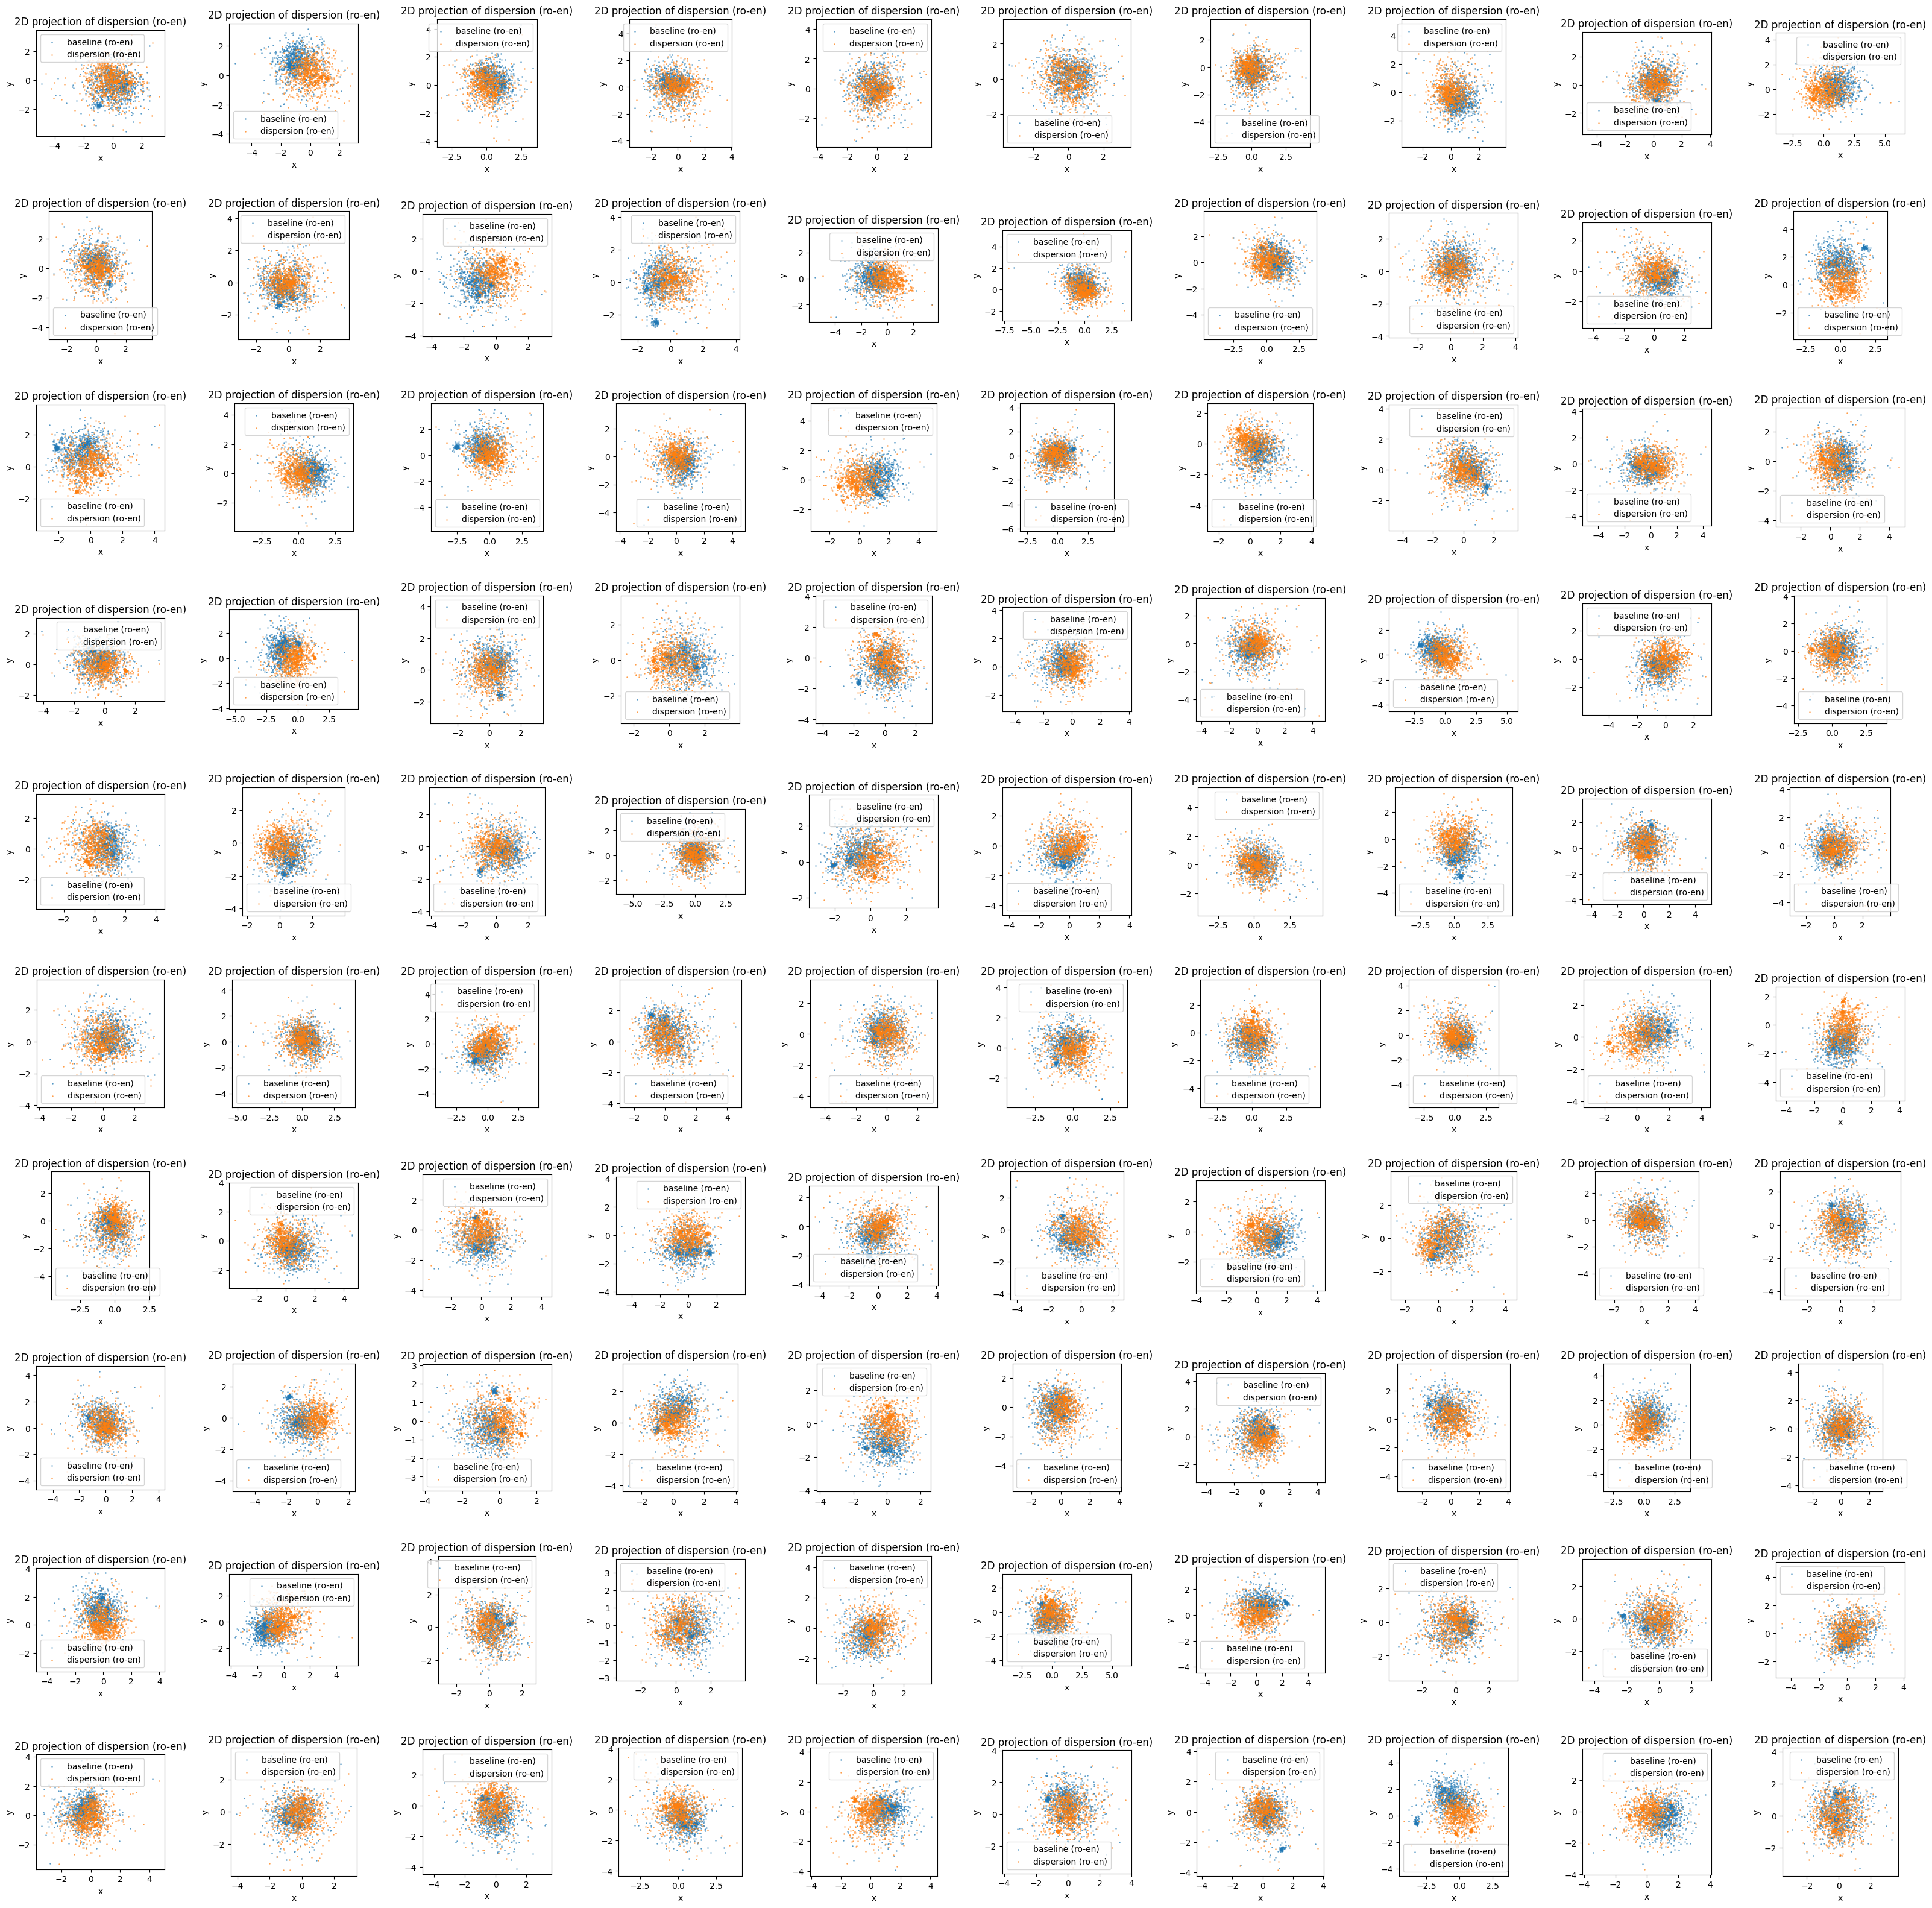

In [15]:
def random_2d_projection(embedding, n_crop=100000, n_sample=1000, seed=0) -> Tuple[np.ndarray, np.ndarray]:
    """
    Project the keys onto a random 2D plane
    Return np.ndarray of shape (n_sample, 2)
    """
    # save values and corresponding cluster_id(feature) 
    keys = embedding.keys[:n_crop]  # use more for final plot
    np.random.seed(seed)
    indices = np.random.choice(len(keys), n_sample, replace=False)
    keys = keys[indices]
    
    # project the keys onto a random 2D plane
    # generate a random 2D matrix
    random_matrix = np.random.randn(2, keys.shape[1])
    random_matrix = random_matrix / np.linalg.norm(random_matrix, axis=1, keepdims=True)
    # project the keys onto the random matrix
    projected_keys = np.dot(keys, random_matrix.T)
    return projected_keys


def plot_2d_projection(ax, embedding, n_crop=100000, n_sample=1000, seed=0):
    """
    Plot the keys in 2D
    """
    # project the keys onto a random 2D plane
    projected_keys = random_2d_projection(embedding, n_crop=n_crop, n_sample=n_sample, seed=seed)
    # plot the keys
    ax.scatter(projected_keys[:, 0], projected_keys[:, 1], alpha=0.5, label=embedding.name, s=1)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_title(f'2D projection of {embedding.name}')
    ax.set_aspect('equal')
    ax.legend()


fig, axes = plt.subplots(10, 10, figsize=(40, 40))
fig.subplots_adjust(hspace=0.5, wspace=0.5)
for i in range(10):
    for j in range(10):
        ax = axes[i, j]
        # plot the keys in 2D
        plot_2d_projection(ax, baseline, n_crop=1000000, n_sample=1000, seed=i*10+j)
        plot_2d_projection(ax, dispersion, n_crop=1000000, n_sample=1000, seed=i*10+j)
plt.show()



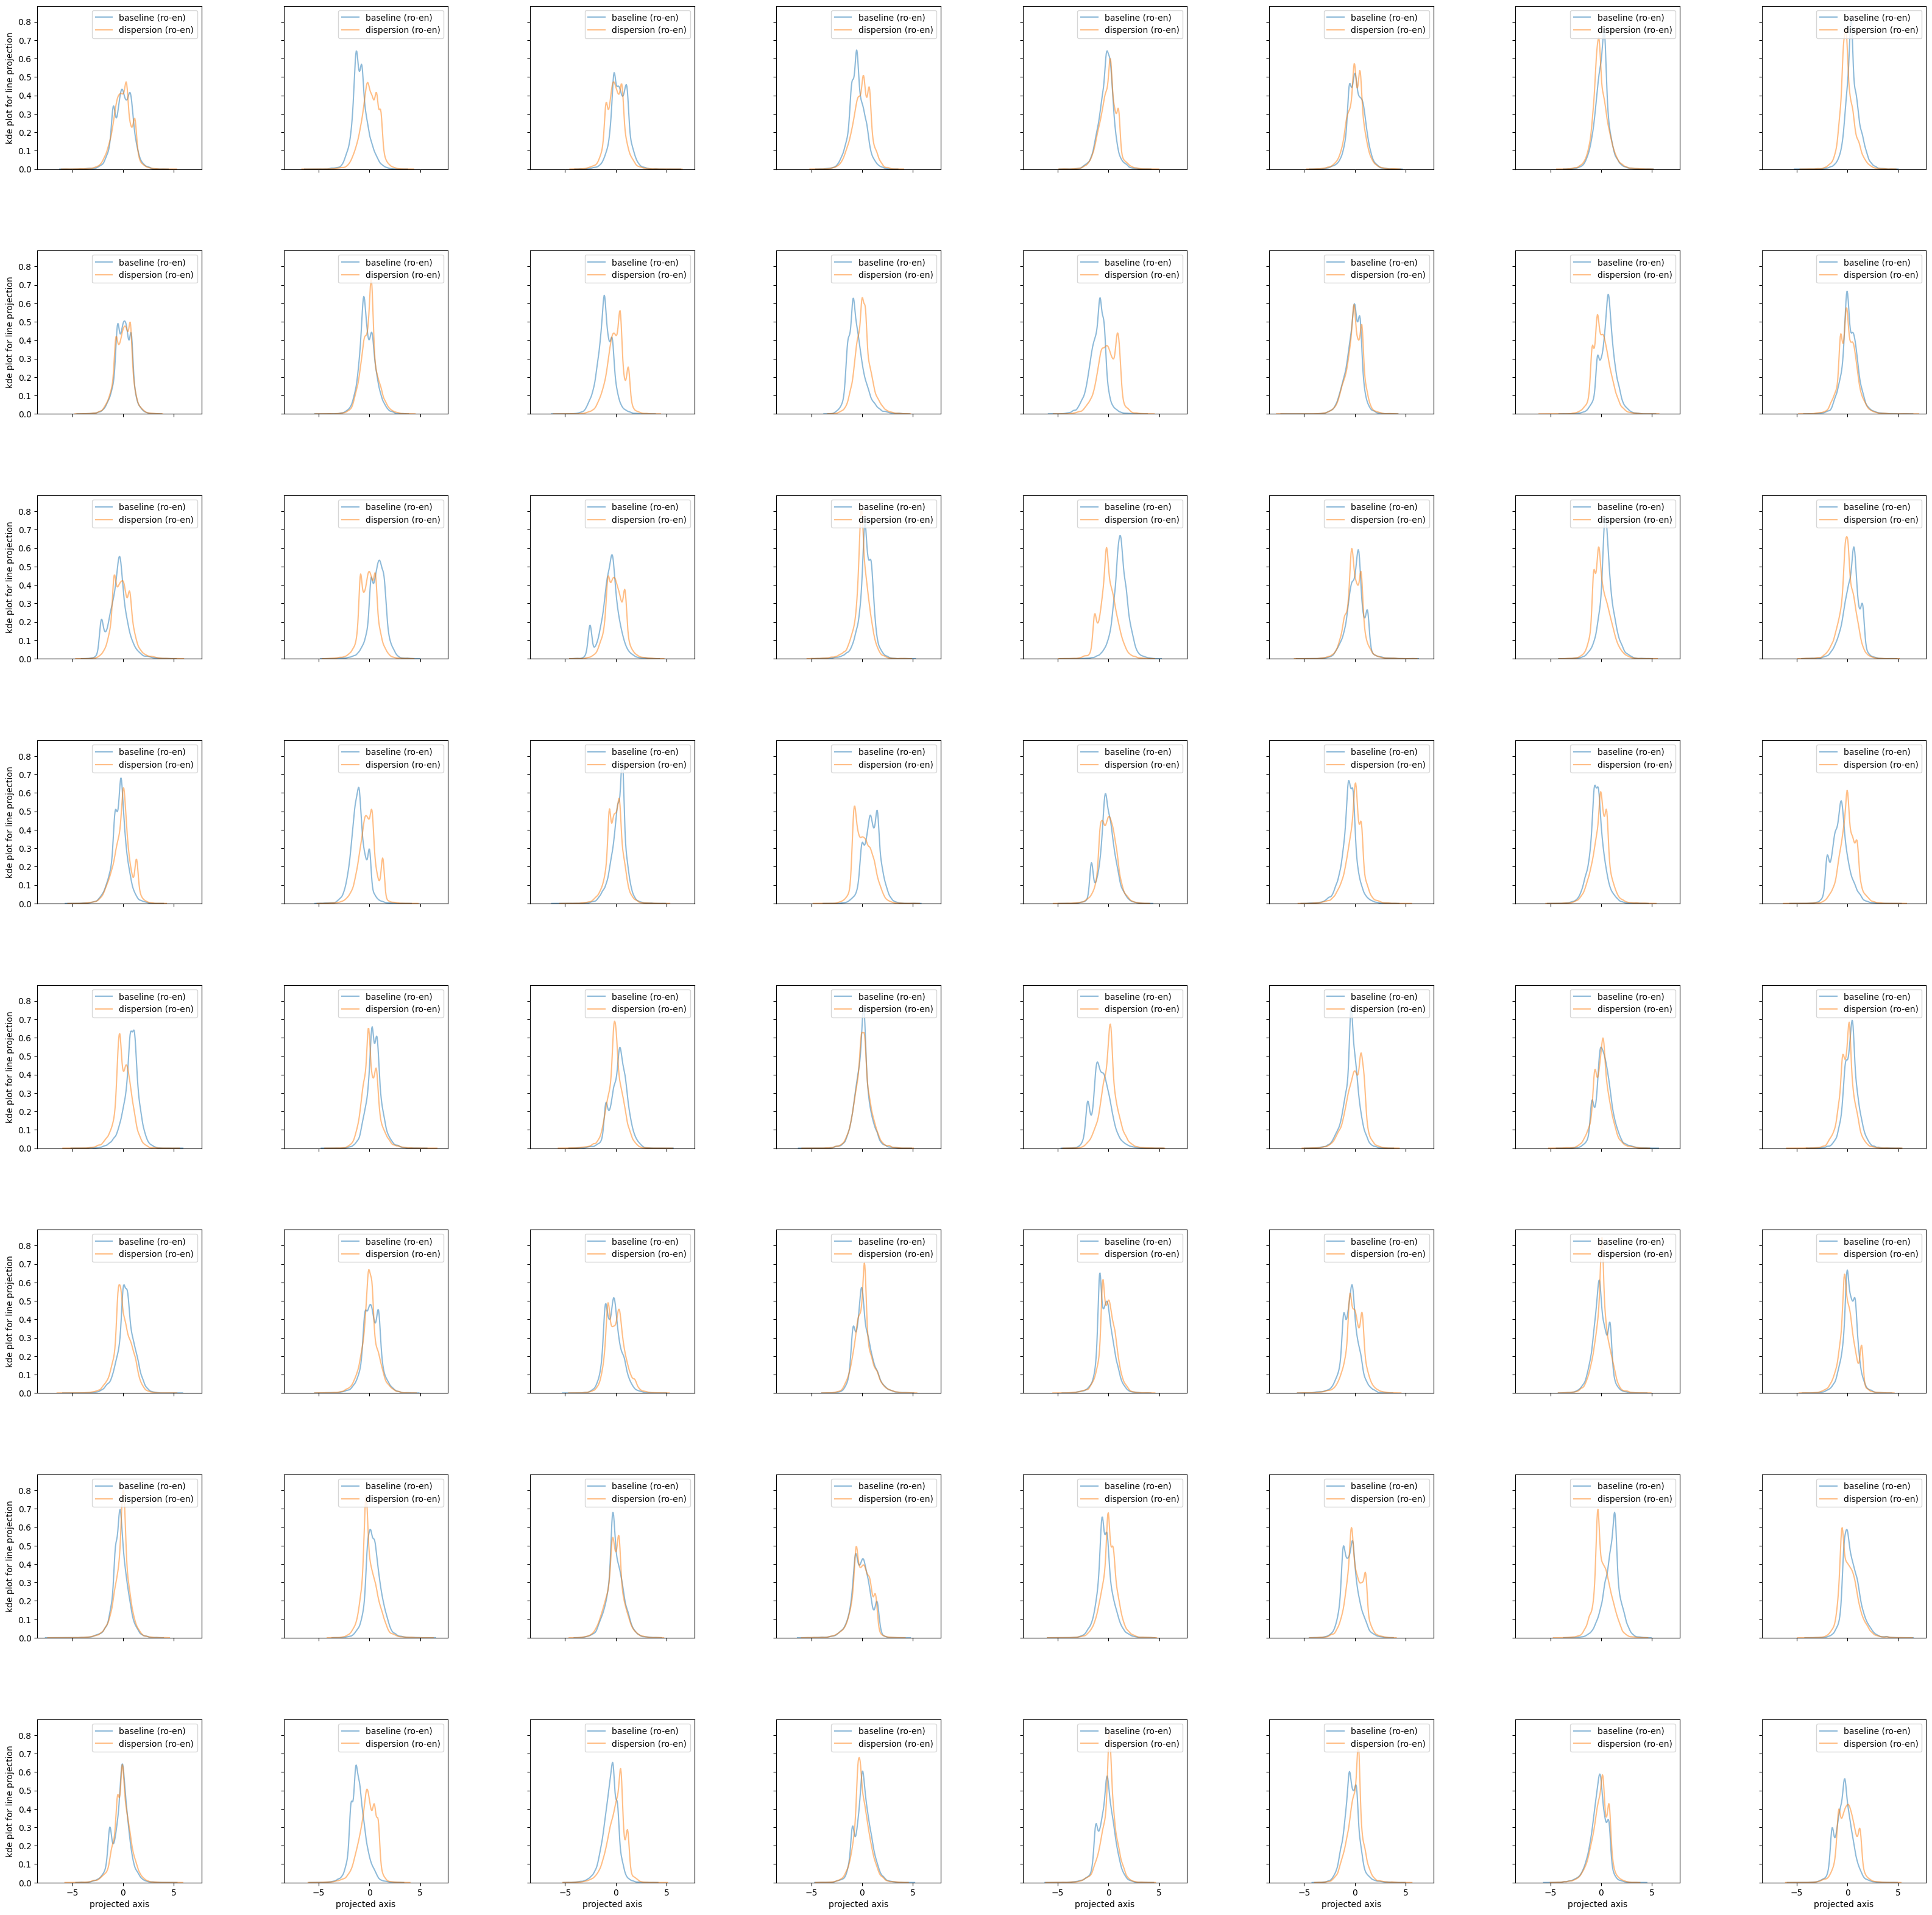

In [3]:
import seaborn as sns

def random_line_projection(embedding, n_crop=100000, n_sample=1000, seed=0) -> Tuple[np.ndarray, np.ndarray]:
    """
    Project the keys onto a random line
    Return np.ndarray of shape (n_sample, 1)
    """
    # save values and corresponding cluster_id(feature) 
    keys = embedding.keys[:n_crop]  # use more for final plot
    np.random.seed(seed)
    indices = np.random.choice(len(keys), n_sample, replace=False)
    keys = keys[indices]
    
    # project the keys onto a random line through the origin
    line = np.random.randn(keys.shape[1])
    line = line / np.linalg.norm(line)
    # project the keys onto the line
    projected_keys = np.dot(keys, line)
    return projected_keys

def plot_line_distribution(ax, embedding, n_crop=100000, n_sample=1000, seed=0):
    """
    Plot the distribution of line projections
    """
    # project the keys onto a random 2D plane
    projected_keys = random_line_projection(embedding, n_crop=n_crop, n_sample=n_sample, seed=seed)
    # make kde plot
    # use gaussian kernel density estimation

    # make sns.kdeplot
    sns.kdeplot(projected_keys, ax=ax, label=embedding.name, alpha=0.5)

    ax.set_xlabel('projected axis')
    ax.set_ylabel('kde plot for line projection')
    ax.legend()
    

N = 8  # N x N grid
fig, axes = plt.subplots(N, N, figsize=(N * 5, N * 5), sharex=True, sharey=True)
fig.subplots_adjust(hspace=0.5, wspace=0.5)
for i in range(N):
    for j in range(N):
        ax = axes[i, j]
        # plot the keys in 2D
        plot_line_distribution(ax, baseline, n_crop=1000000, n_sample=10000, seed=i*10+j)
        plot_line_distribution(ax, dispersion, n_crop=1000000, n_sample=10000, seed=i*10+j)
plt.show()



- projectted plots don't look much different

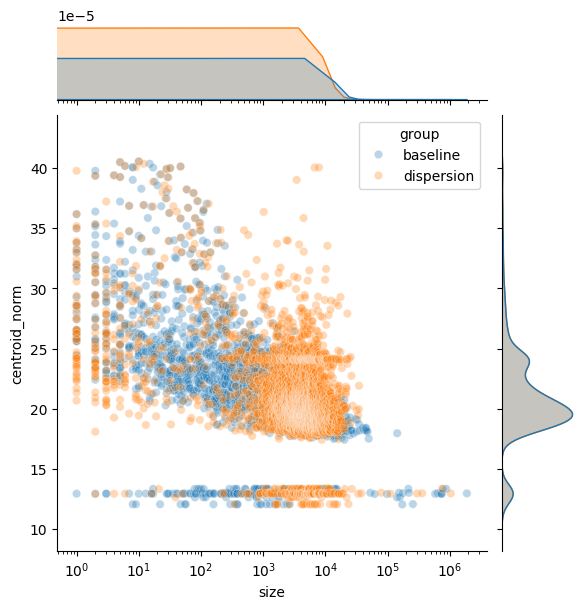

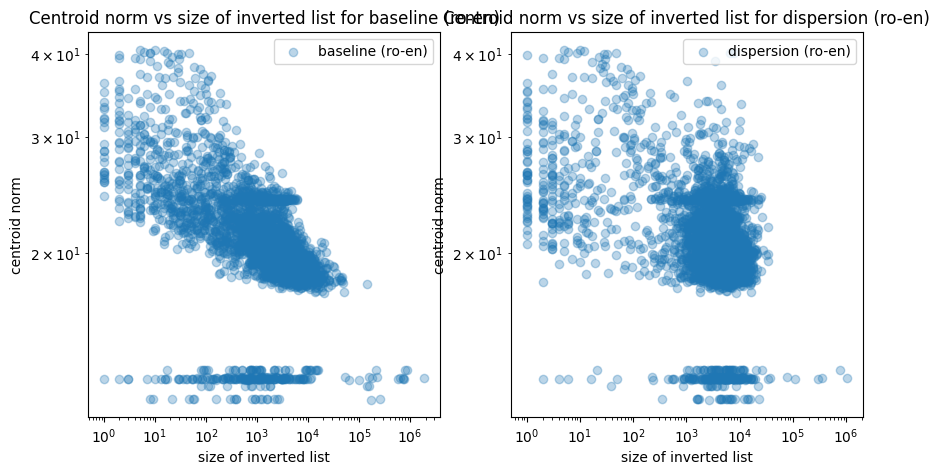

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import scipy as sp

from typing import List, Tuple

def cluster_entropy_with_centroids(embedding: Embedding):
    """
    Returns: IVF cluster sizes
    """
    knn_index = embedding.knn_index
    sizes = []
    # print(knn_index.invlists.code_size)
    # print(knn_index.invlists.nlist)
    for i in range(knn_index.invlists.nlist):
        sizes.append(knn_index.invlists.list_size(i))

    centroids = baseline.knn_index.quantizer.reconstruct_n(0, baseline.knn_index.invlists.nlist)
    centroids.shape
    sizes = np.array(sizes)
    return sizes, centroids

def make_sizes_centroid_norm_plot(baseline: Embedding, dispersion: Embedding):
    """
    Plot the sizes of the IVF clusters for the baseline and dispersion embeddings.
    default: sorted mode by the size of the inverted list
    """
    sizes_baseline, centroids_baseline = cluster_entropy_with_centroids(baseline)
    sizes_dispersion, centroids_dispersion = cluster_entropy_with_centroids(dispersion)
    sorted_indices_baseline = np.argsort(sizes_baseline)
    sorted_indices_dispersion = np.argsort(sizes_dispersion)
    sizes_baseline = sizes_baseline[sorted_indices_baseline]
    sizes_dispersion = sizes_dispersion[sorted_indices_dispersion]
    centroids_baseline_norms = np.linalg.norm(centroids_baseline, axis=1)
    centroids_dispersion_norms = np.linalg.norm(centroids_dispersion, axis=1)
    centroids_baseline_norms = centroids_baseline_norms[sorted_indices_baseline]
    centroids_dispersion_norms = centroids_dispersion_norms[sorted_indices_dispersion]

    # fig, ax = plt.subplots()
    # plt.scatter(sizes_baseline, centroids_baseline_norms, label=baseline.name, alpha=0.3)
    # plt.scatter(sizes_dispersion, centroids_dispersion_norms, label=dispersion.name, alpha=0.3)
    # make a df 2x2

    df = pd.DataFrame({
        "size"          : np.concatenate([sizes_baseline,
                                        sizes_dispersion]),
        "centroid_norm" : np.concatenate([centroids_baseline_norms,
                                        centroids_dispersion_norms]),
        "group"         : (["baseline"]   * len(sizes_baseline) +
                        ["dispersion"] * len(sizes_dispersion))
    })
        # make a scatter plot with different colors

    # g = sns.jointplot(
    #         data=df,
    #         x="size", y="centroid_norm",
    #         hue="group",            # two clouds, different colours
    #         kind="scatter",
    #         alpha=0.30,             # keeps the transparency you had
    #         height=6,               # overall figure size in inches
    #         # marginal_kws=dict(bins=40, fill=False)  # tweak histograms if you like
    # )
    g = sns.jointplot(
        data=df,
        x="size", y="centroid_norm",
        hue="group",
        # kind="scatter",
        alpha=0.3,
        height=6
    )
    plt.xscale('log')

    # # wipe the automatic KDEs
    # g.ax_marg_x.clear()
    # g.ax_marg_y.clear()

    # # redraw explicit histograms
    # sns.histplot(data=df, x="size",
    #             hue="group", bins=100,
    #             element="step", fill=True,
    #             legend=False, ax=g.ax_marg_x, alpha=0.3)

    # sns.histplot(data=df, y="centroid_norm",
    #             hue="group", bins=100,
    #             element="step", fill=True,
    #             legend=False, ax=g.ax_marg_y, alpha=0.3)
    

    plt.show()

    # separate plots
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].scatter(sizes_baseline, centroids_baseline_norms, label=baseline.name, alpha=0.3)
    axes[0].set_xlabel('size of inverted list')

    axes[0].set_ylabel('centroid norm')

    axes[0].set_title(f'Centroid norm vs size of inverted list for {baseline.name}')
    axes[0].set_yscale('log')
    axes[0].set_xscale('log')
    axes[0].legend()
    axes[1].scatter(sizes_dispersion, centroids_dispersion_norms, label=dispersion.name, alpha=0.3)
    axes[1].set_xlabel('size of inverted list')
    axes[1].set_ylabel('centroid norm')
    axes[1].set_title(f'Centroid norm vs size of inverted list for {dispersion.name}')
    axes[1].set_yscale('log')
    axes[1].set_xscale('log')
    axes[1].legend()
    plt.xscale('log')
    plt.show()



########### script. ##########

make_sizes_centroid_norm_plot(baseline, dispersion)

(4096, 512)